# Задание 4.7
## Встреча Ивана и Петра

### Условие:
Иван и Пётр договорились о встрече между 11 и 12 часами. Каждый приходит и ждёт другого до истечения часа, но не более 15 минут. Найдите вероятности событий: $A$ — встреча состоялась; $B$ — не состоялась; $C$ — Ивану не пришлось ждать Петра; $D$ — встреча состоялась после 11:30; $E$ — Иван опоздал на встречу; $F$ — встреча состоялась, когда до конца часа оставалось меньше 5 минут. Постройте график $\hat p(A)$ для $N=150\,000$ и приведите оценку.

### Решение (геометрическая вероятность):
Пусть $x$ — момент прихода Ивана, $y$ — Петра (минуты после 11:00). $\Omega=[0,60]^2$, $\mu(\Omega)=3600$. Встреча происходит, когда первый пришедший дожидается второго: $|x-y|\le15$ (человек, пришедший раньше, ждёт 15 минут). **Момент встречи** — момент прихода второго: $\max(x,y)$.

**Трактовка событий.** $C$: Ивану не пришлось ждать — Пётр пришёл раньше (или одновременно): $y\le x$. $E$: Иван опоздал — он пришёл, когда Пётр уже ушёл: $x-y>15$ (встреча сорвалась из-за опоздания Ивана).

- **A:** $\{|x-y|\le15\}$ — диагональная полоса. Дополнение — два треугольника с катетами $45$: площадь $2\cdot\frac{45^2}{2}=2025$. $\mu(A)=3600-2025=1575$, $\ \mathbb P(A)=\dfrac{1575}{3600}=\dfrac{7}{16}=0{,}4375$.
- **B:** $\mathbb P(B)=1-\mathbb P(A)=\dfrac9{16}=0{,}5625$.
- **C:** $\{y\le x\}$ — половина квадрата: $\mathbb P(C)=\dfrac12$.
- **D:** $\{|x-y|\le15,\ \max(x,y)>30\}$. Из $\mu(A)=1575$ вычтем площадь части с $\max(x,y)\le30$, то есть полосу в квадрате $[0,30]^2$: $900-2\cdot\frac{15^2}{2}=675$. $\mu(D)=1575-675=900$, $\ \mathbb P(D)=\dfrac{900}{3600}=\dfrac14$.
- **E:** $\{x-y>15\}$ — треугольник с катетами 45: $\mathbb P(E)=\dfrac{45^2/2}{3600}=\dfrac{9}{32}=0{,}28125$.
- **F:** $\{|x-y|\le15,\ \max(x,y)>55\}$. Часть с $\max\le55$: $55^2-2\cdot\frac{40^2}{2}=3025-1600=1425$. $\mu(F)=1575-1425=150$, $\ \mathbb P(F)=\dfrac{150}{3600}=\dfrac1{24}\approx0{,}04167$.

*Замечание о трактовке $C$.* Если под $C$ понимать «встреча состоялась и Иван пришёл позже Петра», получим $\{0\le x-y\le15\}$: $\mu=\frac{1575}{2}$, $\mathbb P=\frac7{32}=0{,}21875$ — это другое событие.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

In [2]:
N = 150_000
x = rng.uniform(0, 60, N)                                       # приход Ивана
y = rng.uniform(0, 60, N)                                       # приход Петра
late = np.maximum(x, y)                                          # момент встречи (если она состоялась) — приход второго
events = {
    'A: встреча состоялась':               np.abs(x - y) <= 15,
    'B: встреча не состоялась':            np.abs(x - y) > 15,
    'C: Ивану не пришлось ждать':          y <= x,
    'D: встреча после 11:30':              (np.abs(x - y) <= 15) & (late > 30),
    'E: Иван опоздал (x − y > 15)':        x - y > 15,
    'F: встреча в последние 5 минут':      (np.abs(x - y) <= 15) & (late > 55),
}
exact = {'A': Fraction(7, 16), 'B': Fraction(9, 16), 'C': Fraction(1, 2), 'D': Fraction(1, 4), 'E': Fraction(9, 32), 'F': Fraction(1, 24)}
print(f'{"событие":38s}  точное P     дробь     оценка p̂ (N = {N})')
for (name, h) in events.items():
    P = exact[name[0]]; print(f'{name:38s}  {float(P):.6f}    {str(P):6s}    {h.mean():.6f}   (N(A) = {h.sum()})')

событие                                 точное P     дробь     оценка p̂ (N = 150000)
A: встреча состоялась                   0.437500    7/16      0.439073   (N(A) = 65861)
B: встреча не состоялась                0.562500    9/16      0.560927   (N(A) = 84139)
C: Ивану не пришлось ждать              0.500000    1/2       0.498307   (N(A) = 74746)
D: встреча после 11:30                  0.250000    1/4       0.251153   (N(A) = 37673)
E: Иван опоздал (x − y > 15)            0.281250    9/32      0.279487   (N(A) = 41923)
F: встреча в последние 5 минут          0.041667    1/24      0.041680   (N(A) = 6252)


### Области событий в квадрате и графики относительных частот

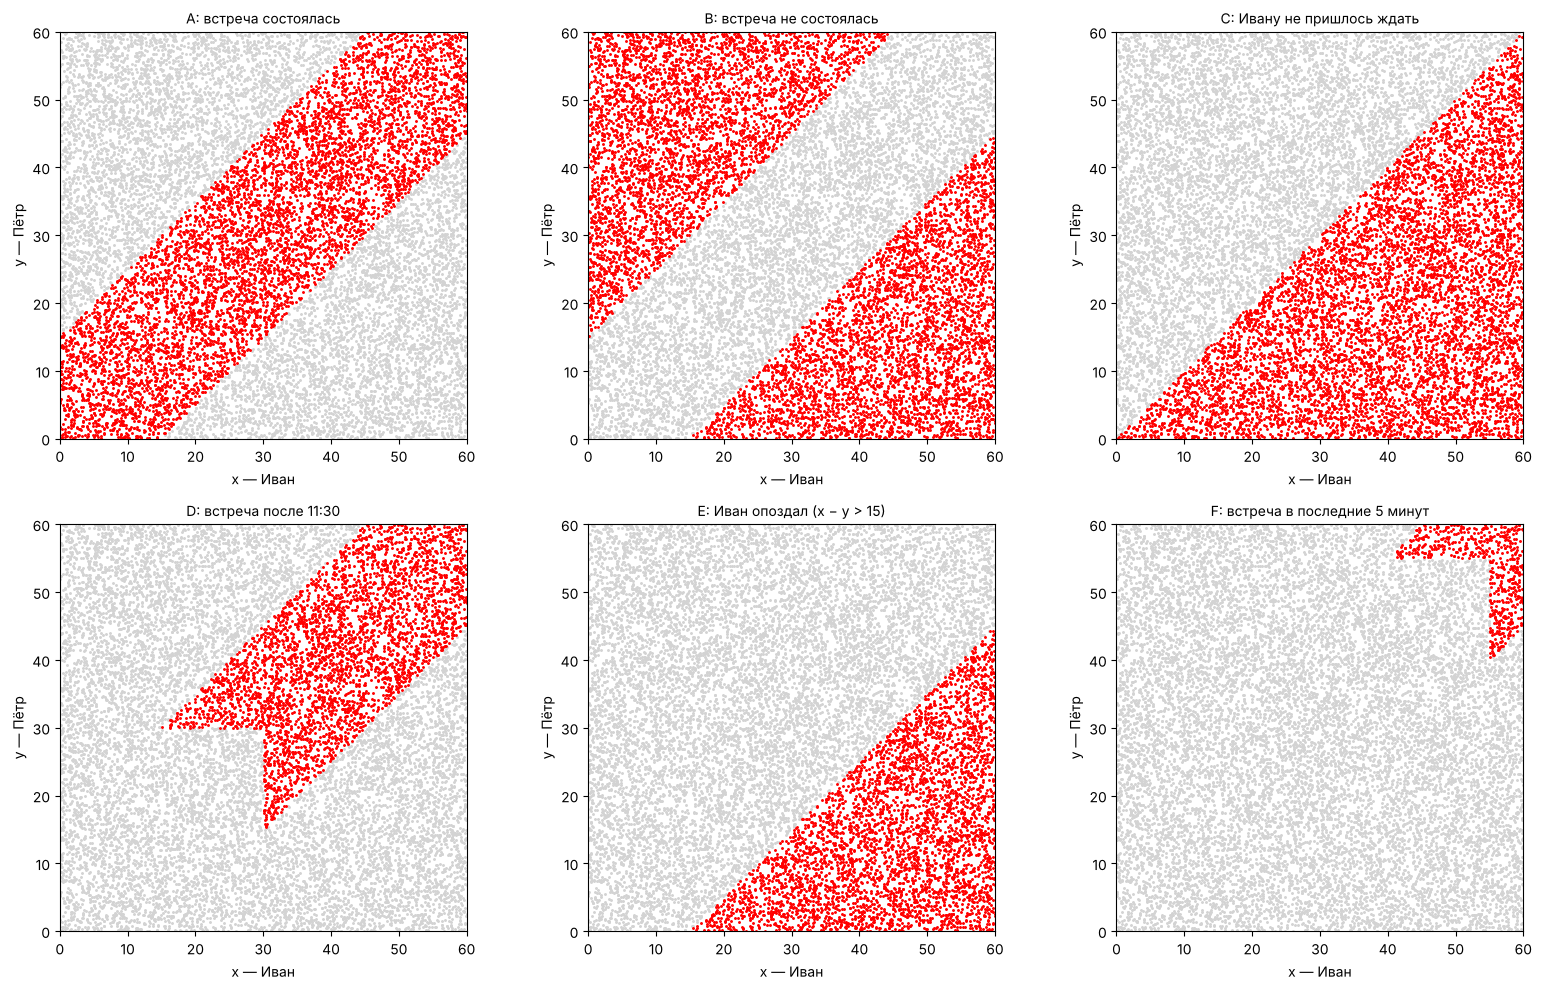

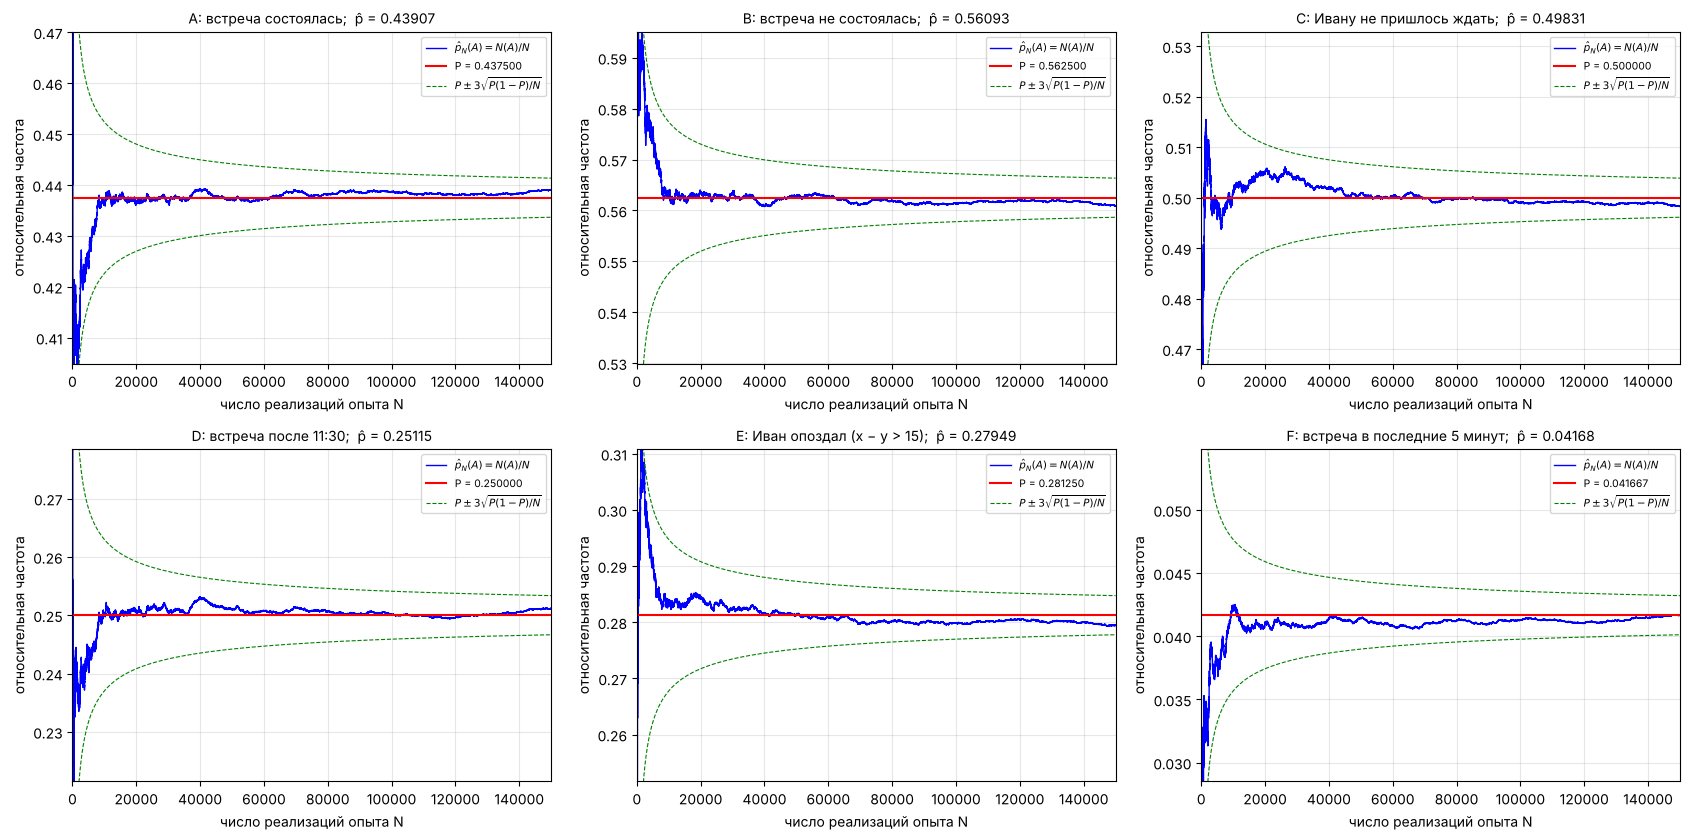

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(16, 10))
m = 15_000
for ax, (name, h) in zip(axs.flat, events.items()):
    ax.scatter(x[:m][~h[:m]], y[:m][~h[:m]], s=1.2, c='lightgray'); ax.scatter(x[:m][h[:m]], y[:m][h[:m]], s=1.2, c='red')
    ax.set_aspect('equal'); ax.set_xlim(0, 60); ax.set_ylim(0, 60); ax.set_xlabel('x — Иван'); ax.set_ylabel('y — Пётр'); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.savefig('task_4_7_regions.png', dpi=120, bbox_inches='tight'); plt.show()

fig, axs = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, (name, h) in zip(axs.flat, events.items()):
    plot_frequency(ax, h, float(exact[name[0]]), name + f';  p̂ = {h.mean():.5f}')
plt.tight_layout(); plt.savefig('task_4_7.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
$\mathbb P(A)=\dfrac7{16}=0{,}4375$, $\ \mathbb P(B)=\dfrac9{16}=0{,}5625$, $\ \mathbb P(C)=\dfrac12$, $\ \mathbb P(D)=\dfrac14$, $\ \mathbb P(E)=\dfrac9{32}=0{,}28125$, $\ \mathbb P(F)=\dfrac1{24}\approx0{,}0417$. Оценка по $N=150\,000$ для $A$ приведена в таблице выше (близка к $0{,}4375$).